In [1]:
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from factor_analyzer.factor_analyzer import calculate_kmo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 0. CARGAR DATASET
# =======================================
# df = pd.read_csv("../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv")
df = pd.read_csv("../data_ready/COLLECT_COMP_dataset_treated.csv")

In [ ]:
# 0. IDENTIFICAR NUMERO DE VALORES EN CADA VARIABLE CATEGORICA
# =======================================

# Ver el número de categorías únicas en cada columna de tipo 'object'
categorical_cols = df.select_dtypes(include=['object', 'category'])
for col in categorical_cols:
    print(f'{col}: {df[col].nunique()} categorías únicas')


STRATUM: 4 categorías únicas
BOOKID: 66 categorías únicas
RDESIGN: 3 categorías únicas
RCORE_TEST: 7 categorías únicas
RCORE_PERF: 4 categorías únicas
RS1_LEV: 3 categorías únicas
RS1_TEST: 7 categorías únicas
RCO1S_PERF: 4 categorías únicas
RS2_LEV: 3 categorías únicas
RS2_TEST: 7 categorías únicas
MPATH: 3 categorías únicas
MCORE_ItemSet: 4 categorías únicas
MCORE_TEST: 17 categorías únicas
MS1_ItemSet: 4 categorías únicas
MS1_TEST: 17 categorías únicas
MS1_LEV: 4 categorías únicas
MS2_ItemSet: 4 categorías únicas
MS2_TEST: 17 categorías únicas
MS2_LEV: 5 categorías únicas
CM033Q01S: 3 categorías únicas
DM033Q01R: 5 categorías únicas
CM474Q01S: 3 categorías únicas
DM474Q01R: 9 categorías únicas
DM155Q02C: 6 categorías únicas
CM155Q01S: 3 categorías únicas
CM155Q04S: 3 categorías únicas
DM155Q04RA: 3 categorías únicas
DM155Q04RB: 3 categorías únicas
DM155Q04RC: 3 categorías únicas
DM155Q04RD: 3 categorías únicas
CM411Q01S: 3 categorías únicas
CM411Q02S: 3 categorías únicas
DM411Q02R: 

In [ ]:
# 0. CARGAR DATASET
# =======================================

from collections import defaultdict

groups = defaultdict(list)

for col in categorical_cols:
    groups[frozenset(df[col].dropna().unique())].append(col)

for categories, cols in groups.items():
    if len(cols) > 1:
        print("Columnas con las mismas categorías:", cols)


Columnas con las mismas categorías: ['RCORE_PERF', 'RCO1S_PERF']
Columnas con las mismas categorías: ['RS1_LEV', 'RS2_LEV']
Columnas con las mismas categorías: ['MCORE_ItemSet', 'MS1_ItemSet', 'MS2_ItemSet']
Columnas con las mismas categorías: ['MCORE_TEST', 'MS1_TEST', 'MS2_TEST']
Columnas con las mismas categorías: ['CM033Q01S', 'CM474Q01S', 'CM155Q01S', 'CM155Q04S', 'CM411Q01S', 'CM411Q02S', 'CM803Q01S', 'CM442Q02S', 'CM034Q01S', 'CM305Q01S', 'CM496Q01S', 'CM496Q02S', 'CM423Q01S', 'CM192Q01S', 'CM603Q01S', 'CM571Q01S', 'CM564Q01S', 'CM564Q02S', 'CM447Q01S', 'CM273Q01S', 'CM408Q01S', 'CM420Q01S', 'CM446Q01S', 'DM446Q02C', 'CM559Q01S', 'DM828Q02C', 'CM828Q03S', 'CM464Q01S', 'CM800Q01S', 'CM982Q01S', 'CM982Q02S', 'CM982Q03S', 'CM982Q04S', 'CM992Q01S', 'CM992Q02S', 'DM992Q03C', 'CM915Q01S', 'CM915Q02S', 'CM906Q01S', 'DM00KQ02C', 'CM909Q01S', 'CM909Q02S', 'CM909Q03S', 'CM949Q01S', 'CM949Q02S', 'CM00GQ01S', 'DM955Q01C', 'DM955Q02C', 'DM998Q02C', 'CM905Q01S', 'DM905Q02C', 'CM919Q01S', 'CM9

In [ ]:
# ----------------------------
# VERIFICAR ESTRUCTURAS
# ----------------------------
df['ST307Q01JA'].unique()

array(['Missing', 'Strongly agree', 'Agree', 'Disagree',
       'Neither agree nor disagree', 'Strongly disagree'], dtype=object)

In [ ]:
# ----------------------------
# LISTA DE PATRONES LIKERT
# ----------------------------
likert_patterns = [
    ['Strongly agree', 'Agree', 'Disagree', 'Strongly disagree'],
    ['Strongly Agree', 'Agree', 'Disagree', 'Strongly Disagree'],
    ['1', '2', '3', '4'],
    ['1', '2', '3', '4', '5'],
    ['Always', 'Often', 'Sometimes', 'Never'],
    ['All of the time', 'Most of the time', 'Some of the time', 'None of the time'],
    
    # Personales
    ['Missing', 'Strongly agree', 'Agree', 'Strongly disagree', 'Disagree'], # ST267Q01JA
    ['Missing', 'Strongly agree', 'Agree', 'Disagree', 'Neither agree nor disagree', 'Strongly disagree'], # ST307Q01JA
    ['Missing', '0 - No credit', '1 - Full credit'], # CM033Q01S
    ['Missing', 'B', 'D', 'A', 'C'], # DM033Q01R
    ['Missing', '0 - No credit', '1 - Partial credit', '2 - Full credit'], # DM906Q02C
    ['Missing', 'Checked', 'Not Checked'], # DMA114Q03RA
    ['Missing', 'Yes', 'No'], # DMA103Q04RA
    ['Missing', 'Strongly agree', 'Agree', 'Disagree', 'Neither agree nor disagree', 'Strongly disagree'], # ST307Q01JA
]

# Convertir patrones a sets para comparación
likert_sets = [set(p) for p in likert_patterns]

# ----------------------------------------------------------
# FUNCIÓN: IDENTIFICAR COLUMNAS LIKERT Y CONTAR
# ----------------------------------------------------------
def identify_likert_columns(df):
    likert_cols = []
    likert_count_by_pattern = {i: 0 for i in range(len(likert_patterns))}

    for col in df.columns:
        if df[col].dtype == "object":
            unique_vals = set(df[col].dropna().astype(str))

            for idx, pattern_set in enumerate(likert_sets):
                if unique_vals == pattern_set:
                    likert_cols.append(col)
                    likert_count_by_pattern[idx] += 1
                    break

    total_likert = len(likert_cols)
    return likert_cols, total_likert, likert_count_by_pattern

# ----------------------------
# EJEMPLO DE USO
# ----------------------------

likert_cols, total_likert, count_by_pattern = identify_likert_columns(df)

print("Columnas Likert detectadas:", likert_cols)
print("Total de columnas Likert:", total_likert)
print("Cantidad por patrón de escala:")
for i, count in count_by_pattern.items():
    print(f"  Patrón {i+1} ({likert_patterns[i]}): {count}")


Columnas Likert detectadas: ['CM033Q01S', 'DM033Q01R', 'CM474Q01S', 'CM155Q01S', 'CM155Q04S', 'CM411Q01S', 'CM411Q02S', 'DM411Q02R', 'CM803Q01S', 'CM442Q02S', 'CM034Q01S', 'CM305Q01S', 'DM305Q01R', 'CM496Q01S', 'CM496Q02S', 'CM423Q01S', 'DM423Q01R', 'CM192Q01S', 'CM603Q01S', 'CM571Q01S', 'DM571Q01R', 'CM564Q01S', 'DM564Q01R', 'CM564Q02S', 'CM447Q01S', 'DM447Q01R', 'CM273Q01S', 'DM273Q01RA', 'DM273Q01RB', 'DM273Q01RC', 'DM273Q01RD', 'CM408Q01S', 'CM420Q01S', 'CM446Q01S', 'DM446Q02C', 'CM559Q01S', 'DM559Q01R', 'DM828Q02C', 'CM828Q03S', 'CM464Q01S', 'CM800Q01S', 'DM800Q01R', 'CM982Q01S', 'CM982Q02S', 'CM982Q03S', 'CM982Q04S', 'DM982Q04R', 'CM992Q01S', 'CM992Q02S', 'DM992Q03C', 'CM915Q01S', 'DM915Q01R', 'CM915Q02S', 'CM906Q01S', 'DM906Q02C', 'DM00KQ02C', 'CM909Q01S', 'CM909Q02S', 'DM909Q02R', 'CM909Q03S', 'CM949Q01S', 'CM949Q02S', 'DM949Q03C', 'CM00GQ01S', 'DM955Q01C', 'DM955Q02C', 'CM955Q03S', 'DM998Q02C', 'CM905Q01S', 'DM905Q02C', 'CM919Q01S', 'CM919Q02S', 'CM954Q01S', 'DM954Q02C', 'CM95

In [32]:
# PASO 1: SELECCIÓN DE VARIABLES PARA AFE
# ========================================
# Selecciona variables que teóricamente midan constructos psicológicos/educativos
# Ejemplo con variables de PISA sobre motivación y autoeficacia

afe_variables = [
    # Variables de motivación
    'ST352Q06JA', 'ST354Q05JA', 'ST355Q05JA', 'MATHMOT',
    # Variables de autoeficacia
    'CREATEFF', 'SDLEFF', 'EFFORT1', 'EFFORT2', 'MATHEFF', 'MATHEF21',
    # Variables de apoyo escolar
    'FAMSUP', 'TEACHSUP', 'FAMSUPSL', 'ST270Q02JA', 'ST270Q03JA', 
    # Añade más según tu dataset
]

afe_variables = likert_cols # Adicionado para probar con mas variables

# Filtrar solo las variables que existen en tu dataset
afe_variables = [var for var in afe_variables if var in df.columns]
df_afe = df[afe_variables].dropna()

print(f"Variables seleccionadas para AFE: {len(afe_variables)}")
print(f"Observaciones completas: {len(df_afe)}")

Variables seleccionadas para AFE: 1311
Observaciones completas: 6968


In [36]:
# Revisar los tipos de datos y valores únicos
# for col in afe_variables:
#     print(f"{col}: {df[col].dtype}, Valores únicos: {df[col].unique()[:10]}")

ordinal_maps = {
    'ST352Q06JA': {
        'Never': 0,
        'A few times': 1,
        'About once or twice a week': 2,
        'Every day or almost every day': 3,
        'Missing': -1
    },
    'ST354Q05JA': {
        'Strongly disagree': 0,
        'Disagree': 1,
        'Agree': 2,
        'Strongly agree': 3,
        'Missing': -1
    },
    'ST355Q05JA': {
        'Not at all confident': 0,
        'Not very confident': 1,
        'Confident': 2,
        'Very confident': 3,
        'Missing': -1
    },
    'MATHMOT': {
        'Not more motivated to do well in mathematics than other subjects': 0,
        'More motivated to do well in mathematics than other subjects': 1,
        'Missing': -1
    },
    'ST270Q02JA': {
        'Never or almost never': 0,
        'Some lessons': 1,
        'Most lessons': 2,
        'Every lesson': 3,
        'Missing': -1
    },
    'ST270Q03JA': {
        'Never or almost never': 0,
        'Some lessons': 1,
        'Most lessons': 2,
        'Every lesson': 3,
        'Missing': -1
    }
}

# Aplicar los mapeos
# df_afe = df_afe.copy()
df_afe = df.copy()
for col, mapping in ordinal_maps.items():
    df_afe[col] = df_afe[col].map(mapping)


In [39]:
df_afe

,CNTSCHID,CNTSTUID,STRATUM,BOOKID,RDESIGN,RCORE_TEST,RCORE_PERF,RS1_LEV,RS1_TEST,RCO1S_PERF,...,PV2SCIC,PV3SCIC,PV4SCIC,PV5SCIC,PV6SCIC,PV7SCIC,PV8SCIC,PV9SCIC,PV10SCIC,VER_DAT
0,60400034.0,60400002.0,PER01,Form 5,Design A (Stage1 then Stage2),Testlet 1,Low Level,Low,Testlet 14,Low Level,...,384.275,365.352,310.953,375.097,302.405,346.531,398.469,405.563,364.602,02MAY23:13:48:32
1,60400267.0,60400006.0,PER02,Form 15,Not used,Not used,Not used,Not used,Not used,Not used,...,408.801,419.913,328.540,352.137,371.997,384.288,385.746,338.499,358.010,02MAY23:13:48:33
2,60400224.0,60400008.0,PER01,Form 43,Not used,Not used,Not used,Not used,Not used,Not used,...,264.028,274.269,244.464,255.180,336.813,311.251,384.335,304.553,315.926,02MAY23:13:48:32
3,60400187.0,60400010.0,PER02,Form 4,Design A (Stage1 then Stage2),Testlet 1,Medium Level,Low,Testlet 14,Low Level,...,318.274,306.316,326.937,286.273,302.026,359.725,339.249,315.577,372.093,02MAY23:13:48:33
4,60400102.0,60400011.0,PER03,Form 24,Not used,Not used,Not used,Not used,Not used,Not used,...,419.836,462.336,393.296,396.027,415.945,422.710,411.513,431.318,400.626,02MAY23:13:48:33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6963,60400176.0,60409527.0,PER01,Form 44,Not used,Not used,Not used,Not used,Not used,Not used,...,409.846,423.159,384.212,427.170,413.777,383.592,327.241,393.202,463.055,02MAY23:13:48:32
6964,60400010.0,60409529.0,PER02,Form 9,Design A (Stage1 then Stage2),Testlet 3,Medium Level,High,Testlet 13,Low Level,...,416.026,402.931,367.748,420.649,398.087,363.265,436.983,434.046,362.291,02MAY23:13:48:33
6965,60400277.0,60409531.0,PER03,Form 8,Design B (Stage2 then Stage1),Testlet 5,Medium Level,High,Testlet 12,Medium Level,...,446.015,434.848,451.765,448.430,455.609,434.954,487.241,410.435,493.333,02MAY23:13:48:34
6966,60400177.0,60409533.0,PER02,Form 22,Not used,Not used,Not used,Not used,Not used,Not used,...,401.932,419.569,403.357,409.057,408.815,427.045,443.615,421.701,420.300,02MAY23:13:48:33


In [22]:
# PASO 2: VERIFICACIÓN DE SUPUESTOS
# ==================================

# 2.1 Test de esfericidad de Bartlett
# H0: La matriz de correlación es una matriz identidad
chi_square_value, p_value = calculate_bartlett_sphericity(df_afe)
print(f'\nTest de Bartlett:')
print(f'Chi-cuadrado: {chi_square_value:.2f}')
print(f'p-value: {p_value:.4f}')
if p_value < 0.05:
    print("✓ Se rechaza H0: Las variables están correlacionadas (bueno para AFE)")
else:
    print("✗ No se rechaza H0: Las variables no están suficientemente correlacionadas")

# 2.2 Kaiser-Meyer-Olkin (KMO)
# Mide la adecuación muestral para AFE
kmo_all, kmo_model = calculate_kmo(df_afe)
print(f'\nKMO General: {kmo_model:.3f}')
print("Interpretación KMO:")
print("  > 0.9: Excelente")
print("  0.8-0.9: Bueno")
print("  0.7-0.8: Aceptable")
print("  0.6-0.7: Mediocre")
print("  < 0.6: Inadecuado")

# KMO por variable
kmo_per_variable = pd.DataFrame({
    'Variable': afe_variables,
    'KMO': kmo_all
})
print("\nKMO por variable (las < 0.5 deberían eliminarse):")
print(kmo_per_variable[kmo_per_variable['KMO'] < 0.6])


Test de Bartlett:
Chi-cuadrado: 32927.97
p-value: 0.0000
✓ Se rechaza H0: Las variables están correlacionadas (bueno para AFE)

KMO General: 0.687
Interpretación KMO:
  > 0.9: Excelente
  0.8-0.9: Bueno
  0.7-0.8: Aceptable
  0.6-0.7: Mediocre
  < 0.6: Inadecuado

KMO por variable (las < 0.5 deberían eliminarse):
  Variable       KMO
6  EFFORT1  0.520361
7  EFFORT2  0.530630


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\d

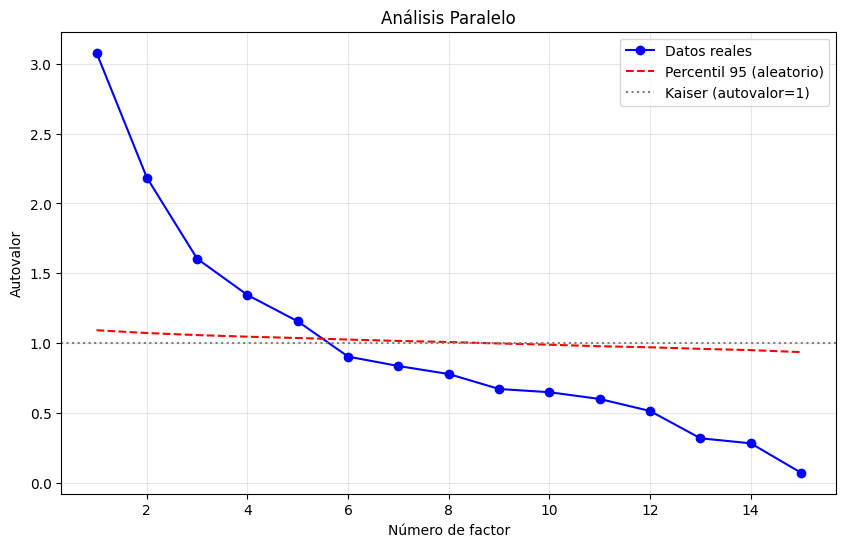


Número de factores sugerido por análisis paralelo: 5


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


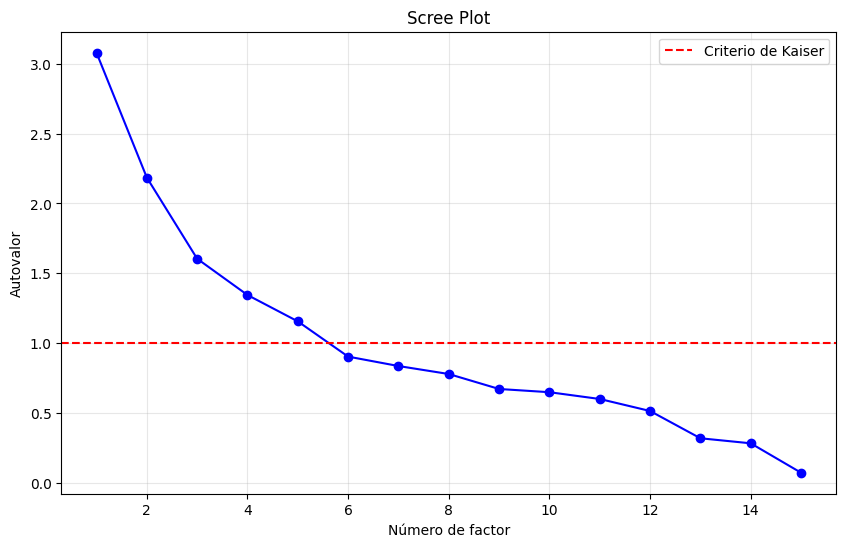

In [25]:
# PASO 3: DETERMINAR NÚMERO DE FACTORES
# =====================================

# 3.1 Análisis paralelo (más robusto)
from factor_analyzer import FactorAnalyzer
# from factor_analyzer.utils import random_correlation_matrix

def parallel_analysis(df, n_iterations=100):
    """Análisis paralelo para determinar número de factores"""
    n_obs, n_vars = df.shape
    
    # Calcular autovalores reales
    fa_real = FactorAnalyzer(n_factors=n_vars, rotation=None)
    fa_real.fit(df)
    ev_real = fa_real.get_eigenvalues()[0]
    
    # Generar autovalores aleatorios
    ev_simulated = np.zeros((n_iterations, n_vars))
    for i in range(n_iterations):
        random_data = np.random.normal(size=(n_obs, n_vars))
        fa_sim = FactorAnalyzer(n_factors=n_vars, rotation=None)
        fa_sim.fit(pd.DataFrame(random_data))
        ev_simulated[i, :] = fa_sim.get_eigenvalues()[0]
    
    # Percentil 95 de autovalores simulados
    ev_95 = np.percentile(ev_simulated, 95, axis=0)
    
    # Determinar número de factores
    n_factors = np.sum(ev_real > ev_95)
    
    # Visualización
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(ev_real)+1), ev_real, 'bo-', label='Datos reales')
    plt.plot(range(1, len(ev_95)+1), ev_95, 'r--', label='Percentil 95 (aleatorio)')
    plt.axhline(y=1, color='gray', linestyle=':', label='Kaiser (autovalor=1)')
    plt.xlabel('Número de factor')
    plt.ylabel('Autovalor')
    plt.title('Análisis Paralelo')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    return n_factors

n_factors_parallel = parallel_analysis(df_afe)
print(f"\nNúmero de factores sugerido por análisis paralelo: {n_factors_parallel}")

# 3.2 Scree plot
fa = FactorAnalyzer(n_factors=len(afe_variables), rotation=None)
fa.fit(df_afe)
ev, v = fa.get_eigenvalues()

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(ev)+1), ev, 'bo-')
plt.axhline(y=1, color='r', linestyle='--', label='Criterio de Kaiser')
plt.xlabel('Número de factor')
plt.ylabel('Autovalor')
plt.title('Scree Plot')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
# PASO 4: EXTRACCIÓN DE FACTORES
# ===============================

# Usar el número de factores determinado
n_factors = n_factors_parallel  # o ajusta manualmente basado en teoría

# Probar diferentes métodos de rotación
rotations = ['varimax', 'promax', 'oblimin']
results = {}

for rotation in rotations:
    fa = FactorAnalyzer(n_factors=n_factors, rotation=rotation, method='principal')
    fa.fit(df_afe)
    
    # Guardar resultados
    results[rotation] = {
        'loadings': fa.loadings_,
        'communalities': fa.get_communalities(),
        'uniqueness': fa.get_uniquenesses(),
        'variance': fa.get_factor_variance()
    }
    
    print(f"\n{'='*50}")
    print(f"ROTACIÓN: {rotation.upper()}")
    print(f"{'='*50}")
    
    # Matriz de cargas factoriales
    loadings_df = pd.DataFrame(
        fa.loadings_,
        index=afe_variables,
        columns=[f'Factor{i+1}' for i in range(n_factors)]
    )
    
    # Mostrar solo cargas > 0.3
    def highlight_loadings(val):
        if abs(val) > 0.5:
            return 'font-weight: bold; color: red'
        elif abs(val) > 0.3:
            return 'font-weight: bold; color: blue'
        return ''
    
    print("\nCargas factoriales (>0.3 en azul, >0.5 en rojo):")
    display(loadings_df.style.applymap(highlight_loadings))
    
    # Varianza explicada
    variance = fa.get_factor_variance()
    variance_df = pd.DataFrame(variance, 
                              index=['Varianza', 'Proporción', 'Acumulada'],
                              columns=[f'Factor{i+1}' for i in range(n_factors)])
    print("\nVarianza explicada:")
    print(variance_df)

c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



ROTACIÓN: VARIMAX

Cargas factoriales (>0.3 en azul, >0.5 en rojo):


C:\Users\max_a\AppData\Local\Temp\ipykernel_39780\3653750460.py:43: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(loadings_df.style.applymap(highlight_loadings))


,Factor1,Factor2,Factor3,Factor4,Factor5
ST352Q06JA,0.077036,-0.037768,0.733920,-0.015991,-0.091093
ST354Q05JA,0.074239,0.025777,0.701669,0.019668,0.130156
ST355Q05JA,0.077174,0.112705,0.760185,0.023085,0.083960
MATHMOT,0.644747,-0.054676,0.409461,-0.054751,-0.124846
CREATEFF,0.024197,0.534806,-0.003490,0.033485,0.263169
SDLEFF,-0.029683,0.391597,0.041084,0.001112,0.357826
EFFORT1,0.002515,-0.001817,-0.051547,0.824951,0.087219
EFFORT2,0.041602,0.052307,0.068386,0.821057,-0.041099
MATHEFF,0.040301,0.864203,0.055180,0.007837,-0.034499
MATHEF21,0.084072,0.873098,0.012300,0.024668,0.044892



Varianza explicada:
            Factor1   Factor2   Factor3   Factor4   Factor5
Varianza    2.61225  2.027674  1.898123  1.373331  1.456195
Proporción  0.17415  0.135178  0.126542  0.091555  0.097080
Acumulada   0.17415  0.309328  0.435870  0.527425  0.624505

ROTACIÓN: PROMAX

Cargas factoriales (>0.3 en azul, >0.5 en rojo):


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\max_a\AppData\Local\Temp\ipykernel_39780\3653750460.py:43: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(loadings_df.style.applymap(highlight_loadings))


,Factor1,Factor2,Factor3,Factor4,Factor5
ST352Q06JA,0.019687,-0.015912,0.733206,0.001650,-0.074772
ST354Q05JA,0.008257,-0.007670,0.707944,0.026621,0.150564
ST355Q05JA,0.003702,0.099021,0.765149,0.030791,0.081230
MATHMOT,0.630721,-0.048033,0.342177,-0.057922,-0.133203
CREATEFF,-0.008708,0.507262,-0.000934,0.008823,0.163014
SDLEFF,-0.063360,0.330056,0.052673,-0.021468,0.303915
EFFORT1,-0.022387,-0.055445,-0.024380,0.827304,0.056756
EFFORT2,0.009037,0.036773,0.088882,0.828489,-0.094332
MATHEFF,-0.001265,0.944949,0.045168,-0.012986,-0.236408
MATHEF21,0.043567,0.930741,-0.000153,-0.001472,-0.154824



Varianza explicada:
             Factor1   Factor2   Factor3   Factor4   Factor5
Varianza    2.604581  2.180411  1.866360  1.382618  1.588748
Proporción  0.173639  0.145361  0.124424  0.092175  0.105917
Acumulada   0.173639  0.318999  0.443423  0.535598  0.641515

ROTACIÓN: OBLIMIN

Cargas factoriales (>0.3 en azul, >0.5 en rojo):


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\max_a\AppData\Local\Temp\ipykernel_39780\3653750460.py:43: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(loadings_df.style.applymap(highlight_loadings))


,Factor1,Factor2,Factor3,Factor4,Factor5
ST352Q06JA,0.042109,-0.026150,0.729140,-0.002701,-0.079544
ST354Q05JA,0.025893,0.002967,0.701409,0.024821,0.142225
ST355Q05JA,0.021533,0.098099,0.758384,0.028416,0.091524
MATHMOT,0.645829,-0.051968,0.322456,-0.055519,-0.138655
CREATEFF,-0.023948,0.500202,-0.005984,0.013123,0.241487
SDLEFF,-0.075429,0.342791,0.049343,-0.017171,0.349610
EFFORT1,-0.021144,-0.043998,-0.039935,0.825916,0.055230
EFFORT2,0.013932,0.029790,0.072634,0.825588,-0.077898
MATHEFF,-0.019031,0.880947,0.041437,-0.011098,-0.078110
MATHEF21,0.023636,0.875945,-0.006099,0.001869,-0.000249



Varianza explicada:
             Factor1   Factor2   Factor3   Factor4   Factor5
Varianza    2.629660  1.949736  1.835092  1.375791  1.469408
Proporción  0.175311  0.129982  0.122339  0.091719  0.097961
Acumulada   0.175311  0.305293  0.427633  0.519352  0.617313


In [27]:
# PASO 5: INTERPRETACIÓN Y ETIQUETADO DE FACTORES
# ================================================

# Usar la mejor rotación (generalmente varimax para factores independientes)
best_rotation = 'varimax'
fa_final = FactorAnalyzer(n_factors=n_factors, rotation=best_rotation, method='principal')
fa_final.fit(df_afe)

# Crear dataframe de cargas para interpretación
loadings_final = pd.DataFrame(
    fa_final.loadings_,
    index=afe_variables,
    columns=[f'Factor{i+1}' for i in range(n_factors)]
)

# Identificar items dominantes por factor (carga > 0.4)
for i in range(n_factors):
    print(f"\n{'='*50}")
    print(f"FACTOR {i+1}")
    print(f"{'='*50}")
    factor_items = loadings_final[f'Factor{i+1}'].abs().sort_values(ascending=False)
    dominant_items = factor_items[factor_items > 0.4]
    print("Items con carga > 0.4:")
    for item, loading in dominant_items.items():
        print(f"  {item}: {loadings_final.loc[item, f'Factor{i+1}']:.3f}")
    
    # Aquí deberías interpretar basado en el contenido de las preguntas
    print("\nInterpretación sugerida: [Analizar contenido de items]")


FACTOR 1
Items con carga > 0.4:
  ST270Q02JA: 0.948
  ST270Q03JA: 0.946
  MATHMOT: 0.645
  TEACHSUP: 0.605

Interpretación sugerida: [Analizar contenido de items]

FACTOR 2
Items con carga > 0.4:
  MATHEF21: 0.873
  MATHEFF: 0.864
  CREATEFF: 0.535

Interpretación sugerida: [Analizar contenido de items]

FACTOR 3
Items con carga > 0.4:
  ST355Q05JA: 0.760
  ST352Q06JA: 0.734
  ST354Q05JA: 0.702
  MATHMOT: 0.409

Interpretación sugerida: [Analizar contenido de items]

FACTOR 4
Items con carga > 0.4:
  EFFORT1: 0.825
  EFFORT2: 0.821

Interpretación sugerida: [Analizar contenido de items]

FACTOR 5
Items con carga > 0.4:
  FAMSUPSL: 0.784
  FAMSUP: 0.727

Interpretación sugerida: [Analizar contenido de items]


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [32]:
# PASO 6: CÁLCULO DE PUNTUACIONES FACTORIALES
# ===========================================

# Obtener puntuaciones factoriales para cada estudiante
factor_scores = fa_final.transform(df_afe)
factor_scores_df = pd.DataFrame(
    factor_scores,
    columns=[f'Factor_{i+1}_Score' for i in range(n_factors)],
    index=df_afe.index
)

# Añadir al dataset principal
df_with_factors = pd.concat([df, factor_scores_df], axis=1)

print(f"\nPuntuaciones factoriales calculadas y añadidas al dataset")
print(f"Nuevas columnas: {factor_scores_df.columns.tolist()}")

c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



Puntuaciones factoriales calculadas y añadidas al dataset
Nuevas columnas: ['Factor_1_Score', 'Factor_2_Score', 'Factor_3_Score', 'Factor_4_Score', 'Factor_5_Score']


In [33]:
# PASO 7: VALIDACIÓN DE LA SOLUCIÓN FACTORIAL
# ===========================================

# 7.1 Confiabilidad (Alpha de Cronbach) por factor
from scipy.stats import pearsonr

def cronbach_alpha(df):
    """Calcula el alpha de Cronbach"""
    df_corr = df.corr()
    N = df.shape[1]
    rs = np.array([])
    for i, col in enumerate(df_corr.columns):
        sum_ = df_corr[col].values.sum() - 1  # Excluir diagonal
        rs = np.append(rs, sum_)
    mean_r = np.mean(rs) / (N - 1)
    alpha = (N * mean_r) / (1 + (N - 1) * mean_r)
    return alpha

# Calcular alpha para cada factor
for i in range(n_factors):
    # Identificar items del factor
    factor_items = loadings_final[f'Factor{i+1}'].abs()
    items = factor_items[factor_items > 0.4].index.tolist()
    
    if len(items) > 1:
        alpha = cronbach_alpha(df_afe[items])
        print(f"\nFactor {i+1} - Alpha de Cronbach: {alpha:.3f}")
        print("Interpretación: ", end="")
        if alpha >= 0.9:
            print("Excelente")
        elif alpha >= 0.8:
            print("Bueno")
        elif alpha >= 0.7:
            print("Aceptable")
        else:
            print("Cuestionable - considerar revisar items")

# 7.2 Validación con split-half
from sklearn.model_selection import train_test_split

# Dividir muestra
df_train, df_test = train_test_split(df_afe, test_size=0.3, random_state=42)

# AFE en muestra de entrenamiento
fa_train = FactorAnalyzer(n_factors=n_factors, rotation=best_rotation)
fa_train.fit(df_train)

# AFE en muestra de test
fa_test = FactorAnalyzer(n_factors=n_factors, rotation=best_rotation)
fa_test.fit(df_test)

# Comparar estructuras factoriales (correlación de cargas)
for i in range(n_factors):
    corr, p = pearsonr(fa_train.loadings_[:, i], fa_test.loadings_[:, i])
    print(f"Factor {i+1} - Correlación train/test: {corr:.3f} (p={p:.4f})")


Factor 1 - Alpha de Cronbach: 0.810
Interpretación: Bueno

Factor 2 - Alpha de Cronbach: 0.693
Interpretación: Cuestionable - considerar revisar items

Factor 3 - Alpha de Cronbach: 0.639
Interpretación: Cuestionable - considerar revisar items

Factor 4 - Alpha de Cronbach: 0.535
Interpretación: Cuestionable - considerar revisar items

Factor 5 - Alpha de Cronbach: 0.493
Interpretación: Cuestionable - considerar revisar items
Factor 1 - Correlación train/test: 0.999 (p=0.0000)
Factor 2 - Correlación train/test: 0.994 (p=0.0000)
Factor 3 - Correlación train/test: 0.993 (p=0.0000)
Factor 4 - Correlación train/test: 0.998 (p=0.0000)
Factor 5 - Correlación train/test: 0.985 (p=0.0000)


c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\max_a\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [37]:
# PASO 6.5: CREACION DE NUEVO DATASET CON VARIABLES UPDATEADAS Y REDUCIDAS
# ===========================================

def discart_var(df, discart_list):
    # Filtrar solo las columnas que realmente existen
    columnas_existentes = [col for col in discart_list if col in df.columns]
    
    # Crear nuevo DataFrame sin esas variables
    nuevo_df = df.drop(columns=columnas_existentes, errors="ignore")
    
    return nuevo_df

discart_list = [
    'ST270Q02JA', 'ST270Q03JA', 'TEACHSUP', 'MATHMOT', 'MATHEF21', 'MATHEFF', 'CREATEFF', 'ST355Q05JA', 'ST352Q06JA', 'ST354Q05JA', 'MATHMOT',
    'Factor_4_Score', 'Factor_5_Score'
]

df_with_factors_modified = discart_var(df_with_factors, discart_list)

# GENERAR ARCHIVO PARA ANALISIS DE CLASES LATENTES
df_with_factors_modified.to_csv("df_with_factors.csv", index=False)

* Exportar Variables *

In [42]:
n_factors

np.int64(5)

In [38]:
# PASO 6.5: df_afe
# ===========================================

# GENERAR ARCHIVO PARA ANALISIS DE CLASES LATENTES
df_afe.to_csv("df_afe.csv", index=False)